# Fixed → Free Boundary: NCSX example

Demonstrates `fixedbound_to_freeboundary`:
1. Build a fixed-boundary SPECTRE input from the NCSX VMEC wout.
2. Load NCSX coils from simsopt's built-in zoo.
3. Extend the plasma boundary outward to create a computational boundary.
4. Convert to free-boundary and write `freeb_ncsx.toml`.
5. Inspect the mode spectrum and boundary cross-sections.
6. Try running SPECTRE (a fresh object resets Fortran-side memory).

In [10]:
import numpy as np
import matplotlib.pyplot as plt

from simsopt.mhd import Vmec
from simsopt.configs.zoo import get_data

from spectre import SPECTRE
from spectre.converters import simsvmec2spectre, compare_vmec_spectre
from spectre.converters.ch  import (
    fixedbound_to_freeboundary,
    params_to_simsopt_boundary,
    plot_freeboundary_modes,
)

## Step 1 – Fixed-boundary SPECTRE input from VMEC wout

In [11]:
vmec = Vmec("wout_li383_low_res_reference.nc")
params = simsvmec2spectre(vmec, nvol=4, mpol=4, ntor=3, interface_guess="wout")
print(f"nvol={params.physics.nvol}, mpol={params.physics.mpol}, ntor={params.physics.ntor}")
print(f"lfreebound={params.physics.lfreebound}, lconstraint={params.physics.lconstraint}")

nvol=4, mpol=4, ntor=3
lfreebound=0, lconstraint=3


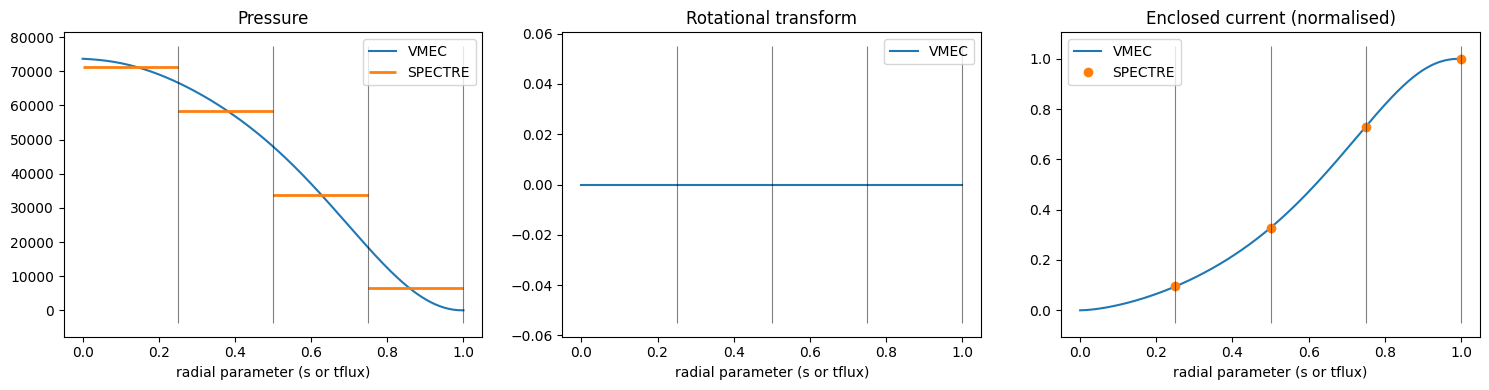

In [12]:
fig, axes = compare_vmec_spectre(vmec, params)
plt.show()

## Step 2 – NCSX coils

`get_data('ncsx')` returns `(base_curves, base_currents, ma, nfp, bs)` for one field period;
`bs` already includes all stellarator-symmetric copies.
`curpol` (μ₀ × net poloidal linking current) is computed automatically inside
`fixedbound_to_freeboundary` from `bs.coils`.

In [13]:
_, _, _, _, bs = get_data("ncsx")
print(f"Number of coils (full torus): {len(bs.coils)}")

Number of coils (full torus): 18


## Step 3 – Build the computational boundary

The boundary extension is separated from the converter so you can tune or replace
the computational boundary independently.  Here we use `extend_via_normal(-0.3)`,
where the negative sign means *outward* in simsopt's convention.

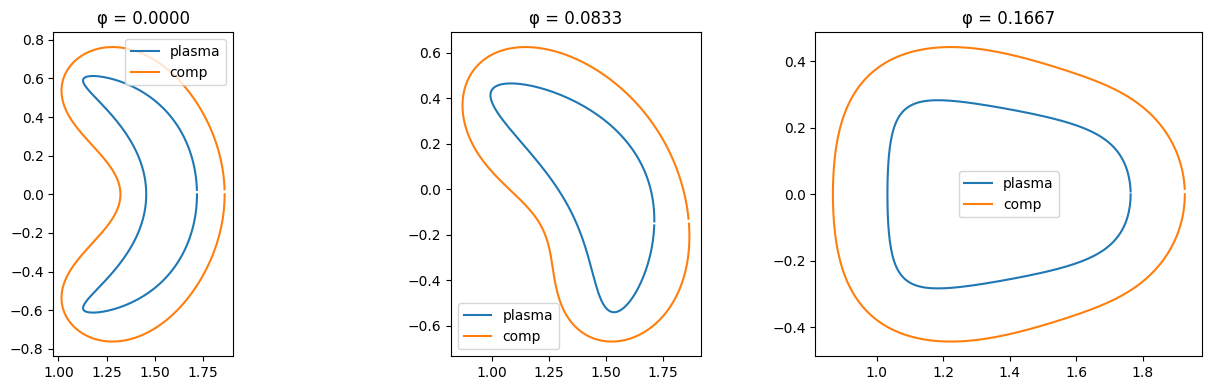

In [14]:
plasma_boundary = params_to_simsopt_boundary(params, which="plasma")
comp_boundary = plasma_boundary.copy()
comp_boundary.extend_via_normal(-0.15)   # negative → outward

# Plot original vs extended cross-sections
nfp = plasma_boundary.nfp
phis = [0.0, 1 / (4 * nfp), 1 / (2 * nfp)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for phi, ax in zip(phis, axes):
    for surf, label in [(plasma_boundary, "plasma"), (comp_boundary, "comp")]:
        cs = surf.cross_section(phi=phi, thetas=200)
        R = np.sqrt(cs[:, 0] ** 2 + cs[:, 1] ** 2)
        ax.plot(R, cs[:, 2], label=label)
    ax.set_aspect("equal")
    ax.set_title(f"φ = {phi:.4f}")
    ax.legend()
fig.tight_layout()

## Step 4 – Convert to free boundary

In [15]:
freeb_params = fixedbound_to_freeboundary(
    params, bs, comp_boundary,
    filename="freeb_ncsx.toml",
)

nvol = freeb_params.physics.nvol
print(f"lfreebound : {freeb_params.physics.lfreebound}")
print(f"nvol       : {nvol}")
print(f"curpol     : {freeb_params.physics.curpol:.4g} T·m")
print(f"phiedge    : {freeb_params.physics.phiedge:.4g} Wb")
print(f"tflux[nvol-1:nvol+1] : {freeb_params.physics.tflux[nvol - 1 : nvol + 1]}")

# Sanity: plasma and comp boundaries must differ
rbc_diff = np.max(np.abs(freeb_params.physics.rbc - freeb_params.physics.rwc))
print(f"max|rbc - rwc| = {rbc_diff:.4g}  (should be > 0)")

lfreebound : 1
nvol       : 4
curpol     : -13.89 T·m
phiedge    : 0.4899 Wb
tflux[nvol-1:nvol+1] : [1.         2.68205191]
max|rbc - rwc| = 0.1542  (should be > 0)


## Step 5 – Mode spectrum and boundary cross-sections

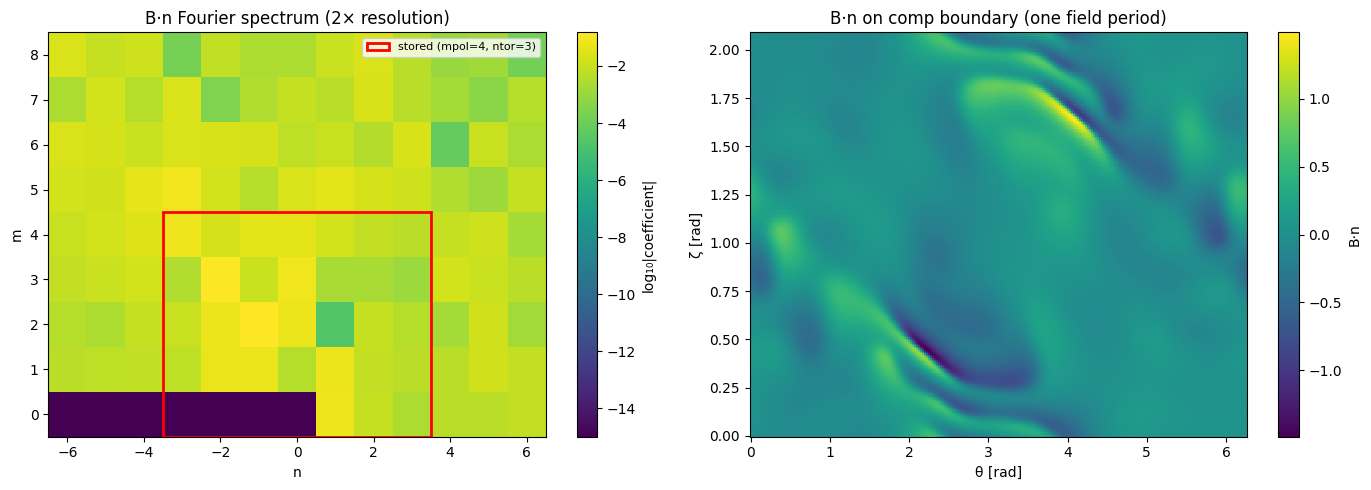

In [16]:
fig = plot_freeboundary_modes(bs, freeb_params)
plt.show()

## Step 6 – Try running SPECTRE

A **fresh** `SPECTRE` object resets Fortran-side memory, so this should work even
if a fixed-boundary object was created in the same kernel above.

In [17]:
spectre = SPECTRE.from_input_params(freeb_params)
spectre.run()

readin :            : 
readin :   10243.37 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  1 ; phiedge=  4.898521140771664E-01 ; curtor=  2.226517876572843E-01 ; curpol= -1.388747893757724E+01 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  3 ; Nvol=  4 ; Mvol=  5 ; Mpol=  4 ; Ntor=  3 
readin :            : pscale=  1.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  3 ; mupf: tol,its=  1.00E-14,   8 
readin :            : Lrad =  8, 8, 8, 8, 8,
readin :            : 
readin :   10243.37 : Linitialize=  0 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  2.000 ; epsilon=  0.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=   0 ; gBntol=  1.00000E-06 ; gBnbld=  6.66000E-01 
rea